In [ ]:
# ============================================================
# Multilayer Neural Network with Backpropagation (TensorFlow)
# MNIST Handwritten Digit Classification
#
# Experiments:
# 1. Logistic Regression
# 2. Decision Tree Classifier
# 3. MLP with One Hidden Layer
# 4. MLP with Two Hidden Layers
# 5. MLP with Three Hidden Layers
#
# Evaluation:
# - Accuracy
# - Loss Curves
# - Training Time
# ============================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import time

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# ============================================================
# 1. LOAD AND PREPROCESS MNIST DATASET
# ============================================================

print("Loading MNIST Dataset...")

(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalize pixel values to [0,1]
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Flatten images for traditional ML models
X_train_flat = X_train.reshape(-1, 784)
X_test_flat = X_test.reshape(-1, 784)

# One-hot encoding for neural networks
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Training Shape:", X_train.shape)
print("Testing Shape :", X_test.shape)

# ============================================================
# 2. LOGISTIC REGRESSION
# ============================================================

print("\nTraining Logistic Regression...")

start = time.time()

lr_model = LogisticRegression(
    max_iter=100,
    solver='lbfgs',
    multi_class='multinomial'
)

lr_model.fit(X_train_flat, y_train)

lr_time = time.time() - start

lr_pred = lr_model.predict(X_test_flat)
lr_acc = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", round(lr_acc * 100, 2), "%")
print("Training Time:", round(lr_time, 2), "seconds")

# ============================================================
# 3. DECISION TREE CLASSIFIER
# ============================================================

print("\nTraining Decision Tree...")

start = time.time()

dt_model = DecisionTreeClassifier(max_depth=20)
dt_model.fit(X_train_flat, y_train)

dt_time = time.time() - start

dt_pred = dt_model.predict(X_test_flat)
dt_acc = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", round(dt_acc * 100, 2), "%")
print("Training Time:", round(dt_time, 2), "seconds")

# ============================================================
# 4. FUNCTION TO BUILD MLP MODELS
# ============================================================

def build_mlp(hidden_layers):

    model = Sequential()

    model.add(Flatten(input_shape=(28, 28)))

    for neurons in hidden_layers:
        model.add(Dense(neurons, activation='relu'))

    # Softmax output layer
    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# ============================================================
# 5. ONE HIDDEN LAYER NETWORK
# ============================================================

print("\nTraining MLP (1 Hidden Layer)...")

mlp1 = build_mlp([128])

start = time.time()

history1 = mlp1.fit(
    X_train,
    y_train_cat,
    validation_split=0.2,
    epochs=10,
    batch_size=128,
    verbose=1
)

time1 = time.time() - start

loss1, acc1 = mlp1.evaluate(X_test, y_test_cat, verbose=0)

print("Accuracy:", round(acc1 * 100, 2), "%")
print("Training Time:", round(time1, 2), "seconds")

# ============================================================
# 6. TWO HIDDEN LAYERS NETWORK
# ============================================================

print("\nTraining MLP (2 Hidden Layers)...")

mlp2 = build_mlp([256, 128])

start = time.time()

history2 = mlp2.fit(
    X_train,
    y_train_cat,
    validation_split=0.2,
    epochs=10,
    batch_size=128,
    verbose=1
)

time2 = time.time() - start

loss2, acc2 = mlp2.evaluate(X_test, y_test_cat, verbose=0)

print("Accuracy:", round(acc2 * 100, 2), "%")
print("Training Time:", round(time2, 2), "seconds")

# ============================================================
# 7. THREE HIDDEN LAYERS NETWORK
# ============================================================

print("\nTraining MLP (3 Hidden Layers)...")

mlp3 = build_mlp([512, 256, 128])

start = time.time()

history3 = mlp3.fit(
    X_train,
    y_train_cat,
    validation_split=0.2,
    epochs=10,
    batch_size=128,
    verbose=1
)

time3 = time.time() - start

loss3, acc3 = mlp3.evaluate(X_test, y_test_cat, verbose=0)

print("Accuracy:", round(acc3 * 100, 2), "%")
print("Training Time:", round(time3, 2), "seconds")

# ============================================================
# 8. PERFORMANCE COMPARISON TABLE
# ============================================================

print("\n================================================")
print("MODEL PERFORMANCE COMPARISON")
print("================================================")

print(f"{'Model':<25} {'Accuracy (%)':<15} {'Time (s)':<10}")
print("-" * 50)

print(f"{'Logistic Regression':<25} {lr_acc*100:<15.2f} {lr_time:<10.2f}")
print(f"{'Decision Tree':<25} {dt_acc*100:<15.2f} {dt_time:<10.2f}")
print(f"{'MLP (1 Hidden Layer)':<25} {acc1*100:<15.2f} {time1:<10.2f}")
print(f"{'MLP (2 Hidden Layers)':<25} {acc2*100:<15.2f} {time2:<10.2f}")
print(f"{'MLP (3 Hidden Layers)':<25} {acc3*100:<15.2f} {time3:<10.2f}")

# ============================================================
# 9. PLOT LOSS CURVES
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(history1.history['loss'], label='1 Hidden Layer')
plt.plot(history2.history['loss'], label='2 Hidden Layers')
plt.plot(history3.history['loss'], label='3 Hidden Layers')

plt.title('Training Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# 10. PLOT VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(history1.history['val_accuracy'],
         label='1 Hidden Layer')

plt.plot(history2.history['val_accuracy'],
         label='2 Hidden Layers')

plt.plot(history3.history['val_accuracy'],
         label='3 Hidden Layers')

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# 11. CONCLUSION
# ============================================================

print("\nCONCLUSION")
print("------------------------------------------------")
print("1. Logistic Regression provides a strong baseline "
      "but is limited to linear decision boundaries.")

print("2. Decision Trees can capture non-linear patterns "
      "but often overfit high-dimensional image data.")

print("3. MLPs use backpropagation and automatic "
      "differentiation to learn complex feature "
      "representations directly from pixels.")

print("4. Increasing hidden layers generally improves "
      "feature extraction and classification performance.")

print("5. Deep learning removes the need for handcrafted "
      "feature engineering by learning hierarchical "
      "representations automatically.")

print("6. Softmax output layer effectively handles "
      "multi-class classification for MNIST digits.")

In [1]:
import numpy as np

import tensorflow as tf

import matplotlib.pyplot as plt

import time

from tensorflow.keras.datasets import mnist

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense, Flatten

from tensorflow.keras.utils import to_categorical

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score

# 1. LOAD AND PREPROCESS MNIST DATASET

In [8]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [9]:
# Normalize pixel values to [0,1]

X_train = X_train.astype('float32') / 255.0

X_test = X_test.astype('float32') / 255.0

In [10]:
# Flatten images for traditional ML models
44
X_train_flat = X_train.reshape(-1, 784)
45
X_test_flat = X_test.reshape(-1, 784)

In [11]:
# One-hot encoding for neural networks

y_train_cat = to_categorical(y_train, 10)

y_test_cat = to_categorical(y_test, 10)

print("Training Shape:", X_train.shape)

print("Testing Shape :", X_test.shape)

Training Shape: (60000, 28, 28)
Testing Shape : (10000, 28, 28)


In [12]:
# Logistic Regression

print("\nTraining Logistic Regression...")

start = time.time()

lr_model = LogisticRegression(

max_iter=100,

solver='lbfgs',

multi_class='multinomial'

)

lr_model.fit(X_train_flat, y_train)

lr_time = time.time() - start

lr_pred = lr_model.predict(X_test_flat)

lr_acc = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", round(lr_acc * 100, 2), "%")

print("Training Time:", round(lr_time, 2), "seconds")


Training Logistic Regression...


C:\Users\MANISHA\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Logistic Regression Accuracy: 92.56 %
Training Time: 13.52 seconds


C:\Users\MANISHA\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Decision Tree classifier

In [13]:
print("\nTraining Decision Tree...")

start = time.time()

dt_model = DecisionTreeClassifier(max_depth=20)
dt_model.fit(X_train_flat, y_train)

dt_time = time.time() - start

dt_pred = dt_model.predict(X_test_flat)
dt_acc = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", round(dt_acc * 100, 2), "%")
print("Training Time:", round(dt_time, 2), "seconds")


Training Decision Tree...
Decision Tree Accuracy: 87.92 %
Training Time: 51.21 seconds


In [14]:
# ============================================================
# 4. FUNCTION TO BUILD MLP MODELS
# ============================================================

def build_mlp(hidden_layers):

    model = Sequential()

    model.add(Flatten(input_shape=(28, 28)))

    for neurons in hidden_layers:
        model.add(Dense(neurons, activation='relu'))

    # Softmax output layer
    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [15]:
# ============================================================
# 5. ONE HIDDEN LAYER NETWORK
# ============================================================

print("\nTraining MLP (1 Hidden Layer)...")

mlp1 = build_mlp([128])

start = time.time()

history1 = mlp1.fit(
    X_train,
    y_train_cat,
    validation_split=0.2,
    epochs=10,
    batch_size=128,
    verbose=1
)

time1 = time.time() - start

loss1, acc1 = mlp1.evaluate(X_test, y_test_cat, verbose=0)

print("Accuracy:", round(acc1 * 100, 2), "%")
print("Training Time:", round(time1, 2), "seconds")


Training MLP (1 Hidden Layer)...


C:\Users\MANISHA\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.8920 - loss: 0.3962 - val_accuracy: 0.9415 - val_loss: 0.2141
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9456 - loss: 0.1894 - val_accuracy: 0.9539 - val_loss: 0.1611
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9598 - loss: 0.1392 - val_accuracy: 0.9615 - val_loss: 0.1330
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9687 - loss: 0.1081 - val_accuracy: 0.9650 - val_loss: 0.1174
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9745 - loss: 0.0894 - val_accuracy: 0.9696 - val_loss: 0.1074
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9793 - loss: 0.0729 - val_accuracy: 0.9700 - val_loss: 0.1003
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9829 - loss: 0.0617 - val_accuracy: 0.9705 - val_loss: 0.0971
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9852 - loss: 0.0528 - val_accuracy: 0

In [16]:
# ============================================================
# 6. TWO HIDDEN LAYERS NETWORK
# ============================================================

print("\nTraining MLP (2 Hidden Layers)...")

mlp2 = build_mlp([256, 128])

start = time.time()

history2 = mlp2.fit(
    X_train,
    y_train_cat,
    validation_split=0.2,
    epochs=10,
    batch_size=128,
    verbose=1
)

time2 = time.time() - start

loss2, acc2 = mlp2.evaluate(X_test, y_test_cat, verbose=0)

print("Accuracy:", round(acc2 * 100, 2), "%")
print("Training Time:", round(time2, 2), "seconds")


Training MLP (2 Hidden Layers)...
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9144 - loss: 0.3025 - val_accuracy: 0.9572 - val_loss: 0.1482
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9670 - loss: 0.1138 - val_accuracy: 0.9686 - val_loss: 0.1068
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9769 - loss: 0.0762 - val_accuracy: 0.9721 - val_loss: 0.0958
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9835 - loss: 0.0537 - val_accuracy: 0.9748 - val_loss: 0.0866
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9879 - loss: 0.0401 - val_accuracy: 0.9734 - val_loss: 0.0851
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9908 - loss: 0.0302 - val_accuracy: 0.9751 - val_loss: 0.0815
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9928 - loss: 0.0230 - val_accuracy: 0.9760 - val_loss: 0.0850
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0

In [17]:
# ============================================================
# 7. THREE HIDDEN LAYERS NETWORK
# ============================================================

print("\nTraining MLP (3 Hidden Layers)...")

mlp3 = build_mlp([512, 256, 128])

start = time.time()

history3 = mlp3.fit(
    X_train,
    y_train_cat,
    validation_split=0.2,
    epochs=10,
    batch_size=128,
    verbose=1
)

time3 = time.time() - start

loss3, acc3 = mlp3.evaluate(X_test, y_test_cat, verbose=0)

print("Accuracy:", round(acc3 * 100, 2), "%")
print("Training Time:", round(time3, 2), "seconds")


Training MLP (3 Hidden Layers)...
Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9246 - loss: 0.2529 - val_accuracy: 0.9563 - val_loss: 0.1340
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9719 - loss: 0.0924 - val_accuracy: 0.9703 - val_loss: 0.0914
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9815 - loss: 0.0575 - val_accuracy: 0.9702 - val_loss: 0.0961
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9871 - loss: 0.0395 - val_accuracy: 0.9747 - val_loss: 0.0830
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9901 - loss: 0.0307 - val_accuracy: 0.9743 - val_loss: 0.0949
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9914 - loss: 0.0260 - val_accuracy: 0.9747 - val_loss: 0.0973
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9930 - loss: 0.0200 - val_accuracy: 0.9752 - val_loss: 0.0928
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accurac

In [18]:
# ============================================================
# 8. PERFORMANCE COMPARISON TABLE
# ============================================================

print("\n================================================")
print("MODEL PERFORMANCE COMPARISON")
print("================================================")

print(f"{'Model':<25} {'Accuracy (%)':<15} {'Time (s)':<10}")
print("-" * 50)

print(f"{'Logistic Regression':<25} {lr_acc*100:<15.2f} {lr_time:<10.2f}")
print(f"{'Decision Tree':<25} {dt_acc*100:<15.2f} {dt_time:<10.2f}")
print(f"{'MLP (1 Hidden Layer)':<25} {acc1*100:<15.2f} {time1:<10.2f}")
print(f"{'MLP (2 Hidden Layers)':<25} {acc2*100:<15.2f} {time2:<10.2f}")
print(f"{'MLP (3 Hidden Layers)':<25} {acc3*100:<15.2f} {time3:<10.2f}")


MODEL PERFORMANCE COMPARISON
Model                     Accuracy (%)    Time (s)  
--------------------------------------------------
Logistic Regression       92.56           13.52     
Decision Tree             87.92           51.21     
MLP (1 Hidden Layer)      97.34           36.06     
MLP (2 Hidden Layers)     97.97           40.08     
MLP (3 Hidden Layers)     98.33           57.80     


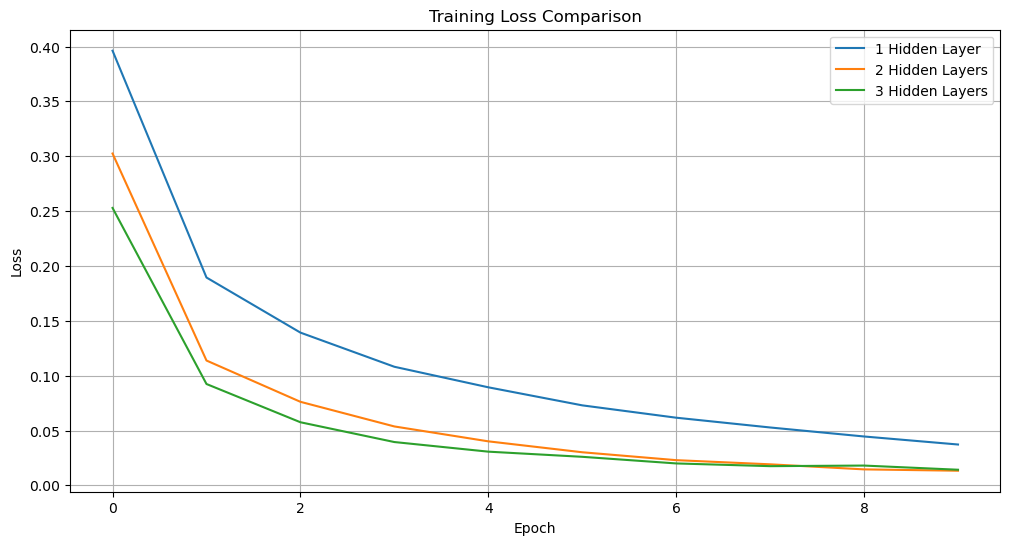

In [19]:
# ============================================================
# 9. PLOT LOSS CURVES
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(history1.history['loss'], label='1 Hidden Layer')
plt.plot(history2.history['loss'], label='2 Hidden Layers')
plt.plot(history3.history['loss'], label='3 Hidden Layers')

plt.title('Training Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

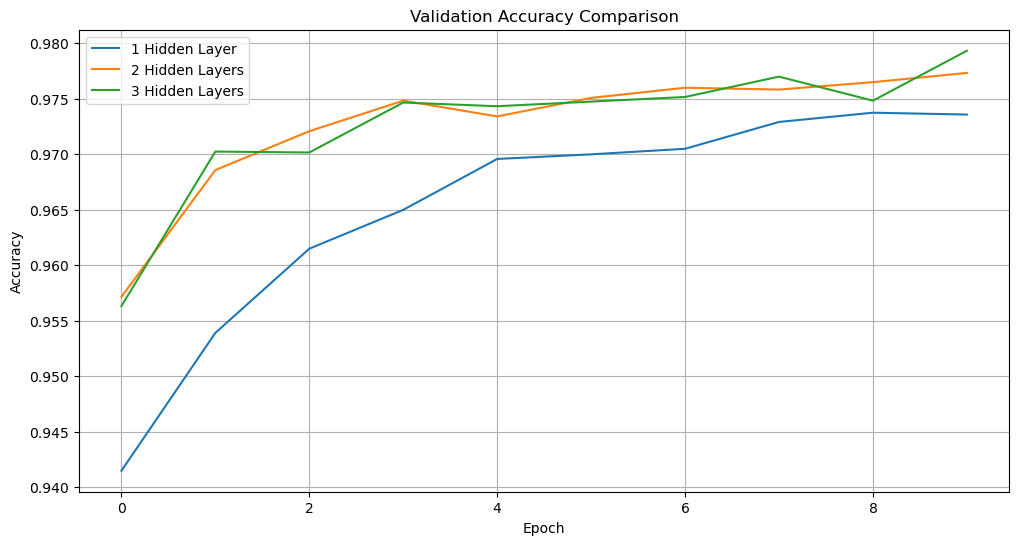

In [20]:
# ============================================================
# 10. PLOT VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(history1.history['val_accuracy'],
         label='1 Hidden Layer')

plt.plot(history2.history['val_accuracy'],
         label='2 Hidden Layers')

plt.plot(history3.history['val_accuracy'],
         label='3 Hidden Layers')

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
# ============================================================
# 11. CONCLUSION
# ============================================================

print("\nCONCLUSION")
print("------------------------------------------------")
print("1. Logistic Regression provides a strong baseline "
      "but is limited to linear decision boundaries.")

print("2. Decision Trees can capture non-linear patterns "
      "but often overfit high-dimensional image data.")

print("3. MLPs use backpropagation and automatic "
      "differentiation to learn complex feature "
      "representations directly from pixels.")

print("4. Increasing hidden layers generally improves "
      "feature extraction and classification performance.")

print("5. Deep learning removes the need for handcrafted "
      "feature engineering by learning hierarchical "
      "representations automatically.")

print("6. Softmax output layer effectively handles "
      "multi-class classification for MNIST digits.")


CONCLUSION
------------------------------------------------
1. Logistic Regression provides a strong baseline but is limited to linear decision boundaries.
2. Decision Trees can capture non-linear patterns but often overfit high-dimensional image data.
3. MLPs use backpropagation and automatic differentiation to learn complex feature representations directly from pixels.
4. Increasing hidden layers generally improves feature extraction and classification performance.
5. Deep learning removes the need for handcrafted feature engineering by learning hierarchical representations automatically.
6. Softmax output layer effectively handles multi-class classification for MNIST digits.
